# Pump P-104: monthly readings, 2026

The readings of an example company's pump, invented for a JupyterLab guide on karandeshmukh.dev. They aren't real equipment data. The expected ranges are those of the example procedure MP-PS104-01.

In [5]:
import pandas as pd

readings = pd.read_csv("readings.csv", parse_dates=["date"])
readings.tail(3)

,date,discharge_pressure_bar,bearing_temp_c,vibration_mm_s,seal_leakage
8,2026-09-16,4.2,64.8,3.9,none
9,2026-10-14,4.0,62.3,4.2,none
10,2026-11-11,3.9,61.7,4.8,visible


In [6]:
limits = {
    "discharge_pressure_bar": (3.8, 4.6),
    "bearing_temp_c": (None, 70.0),
    "vibration_mm_s": (None, 4.5),
}

def outside(row):
    """The readings of one inspection that are outside their expected range."""
    found = [name for name, (low, high) in limits.items()
             if (low is not None and row[name] < low) or (high is not None and row[name] >= high)]
    if row["seal_leakage"] != "none":
        found.append("seal_leakage")
    return ", ".join(found)

readings["outside_range"] = readings.apply(outside, axis=1)
readings[readings["outside_range"] != ""][["date", "outside_range"]]

,date,outside_range
7,2026-08-12,bearing_temp_c
10,2026-11-11,"vibration_mm_s, seal_leakage"


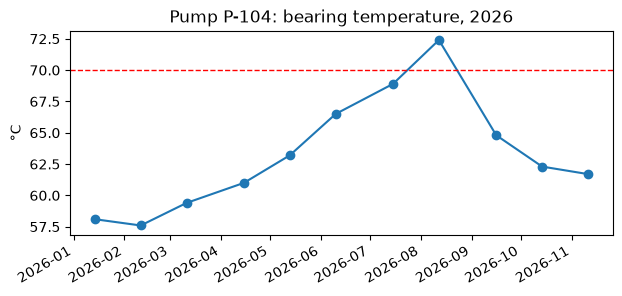

In [3]:
ax = readings.plot(x="date", y="bearing_temp_c", marker="o", legend=False, figsize=(7, 3))
ax.axhline(70, color="red", linestyle="--", linewidth=1)
ax.set_title("Pump P-104: bearing temperature, 2026")
ax.set_xlabel("")
ax.set_ylabel("°C");

In [4]:
print(f"{len(readings)} inspections, {(readings['outside_range'] != '').sum()} with a reading outside its range")

11 inspections, 2 with a reading outside its range
